<a href="https://colab.research.google.com/github/snowycupcake/skills-introduction-to-github/blob/main/sharpe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/mariamwalaa/StocksPortfolioOptimization.git
%cd StocksPortfolioOptimization

Cloning into 'StocksPortfolioOptimization'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 25 (delta 4), reused 19 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 388.29 KiB | 9.96 MiB/s, done.
Resolving deltas: 100% (4/4), done.
/content/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization


In [ ]:
%run scripts/data_collection.py

/content/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization/StocksPortfolioOptimization/scripts/data_collection.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  asset_data = yf.download(symbol, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


KeyError: "['Adj Close'] not in index"

<Figure size 640x480 with 0 Axes>

In [ ]:
portfolio_data = pd.read_csv("data/portfolio_data.csv")
display(portfolio_data)

,AAPL,Date_AAPL,MSFT,Date_MSFT,GOOGL,Date_GOOGL,TSLA,Date_TSLA
0,24.009062,2016-01-04,48.797722,2016-01-04,37.972000,2016-01-04,14.894000,2016-01-04
1,23.407415,2016-01-05,49.020344,2016-01-05,38.076500,2016-01-05,14.895333,2016-01-05
2,22.949339,2016-01-06,48.129879,2016-01-06,37.966499,2016-01-06,14.602667,2016-01-06
3,21.980766,2016-01-07,46.455799,2016-01-07,37.049999,2016-01-07,14.376667,2016-01-07
4,22.096992,2016-01-08,46.598251,2016-01-08,36.545502,2016-01-08,14.066667,2016-01-08
...,...,...,...,...,...,...,...,...
1757,131.299820,2022-12-23,237.112076,2022-12-23,89.230003,2022-12-23,123.150002,2022-12-23
1758,129.477585,2022-12-27,235.354095,2022-12-27,87.389999,2022-12-27,109.099998,2022-12-27
1759,125.504539,2022-12-28,232.940552,2022-12-28,86.019997,2022-12-28,112.709999,2022-12-28
1760,129.059372,2022-12-29,239.376633,2022-12-29,88.449997,2022-12-29,121.820000,2022-12-29


In [ ]:
import yfinance as yf
import pandas as pd
from pathlib import Path

def collect_portfolio_data(symbols, start, end):
    frames = []
    for s in symbols:
        df = yf.download(s, start=start, end=end, auto_adjust=False)
        df = df[['Adj Close']].rename(columns={'Adj Close': s})
        frames.append(df)
    out = pd.concat(frames, axis=1)
    out.index.name = "Date"
    return out

symbols = ["AAPL","MSFT","GOOGL","TSLA"]
start, end = "2016-01-01", "2022-12-31"

df = collect_portfolio_data(symbols, start, end)

Path("data").mkdir(parents=True, exist_ok=True)
df.to_csv("data/portfolio_data.csv", index=True)  # Date saved as index/first column
print("Saved:", df.shape, list(df.columns))


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Saved: (1762, 4) [('AAPL', 'AAPL'), ('MSFT', 'MSFT'), ('GOOGL', 'GOOGL'), ('TSLA', 'TSLA')]


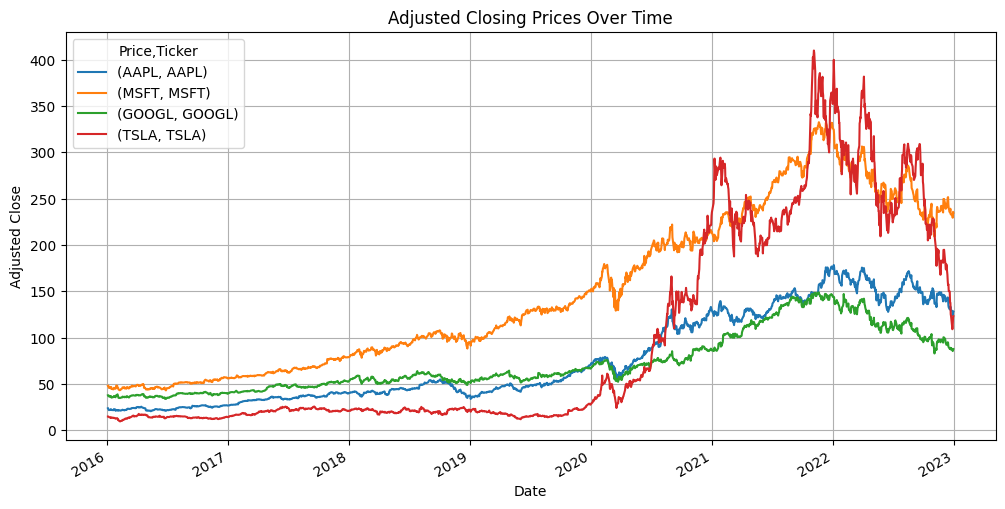

In [ ]:
import matplotlib.pyplot as plt

symbols = ["AAPL","MSFT","GOOGL","TSLA"]
use_cols = [s for s in symbols if s in df.columns]
df[use_cols] = df[use_cols].apply(pd.to_numeric, errors='coerce')

ax = df[use_cols].plot(figsize=(12,6))
ax.set_title("Adjusted Closing Prices Over Time")
ax.set_ylabel("Adjusted Close")
ax.set_xlabel("Date")
ax.grid(True)
plt.show()


In [ ]:
import pandas as pd

df = pd.read_csv("data/portfolio_data.csv", index_col=0, parse_dates=True)
df.columns = df.columns.str.strip()          # remove accidental spaces
print(df.shape)
print(df.columns.tolist()[:10])              # should show ['AAPL','MSFT','GOOGL','TSLA']


(1764, 4)
['AAPL', 'MSFT', 'GOOGL', 'TSLA']


/tmp/ipython-input-4126041488.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv("data/portfolio_data.csv", index_col=0, parse_dates=True)


In [ ]:
portfolio_symbols = ["AAPL", "MSFT", "GOOGL", "TSLA"]


In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Import functions from your scripts
from scripts.data_collection import collect_portfolio_data
from scripts.data_preprocessing import preprocess_portfolio_data
from scripts.portfolio_analysis import calculate_portfolio_metrics
from scripts.optimization import optimize_portfolio

In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Import functions from scripts
from scripts.data_collection import fetch_stock_data
from scripts.data_preprocessing import preprocess_portfolio_data

In [ ]:
stock_symbol = "AAPL"  # Replace with your chosen stock symbol
start_date = "2010-01-01"
end_date = "2020-12-31"
risk_free_rate = 0.03  # Adjust as needed

# Fetch stock data using the imported function
stock_data = fetch_stock_data(stock_symbol, start_date, end_date)

# Display collected stock data
display(stock_data)

/content/StocksPortfolioOptimization/scripts/data_collection.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(symbol, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2010-01-04,6.424606,6.439316,6.375673,6.407194,493729600
2010-01-05,6.435713,6.472038,6.401790,6.442318,601904800
2010-01-06,6.333342,6.461228,6.326738,6.435711,552160000
2010-01-07,6.321636,6.364265,6.275705,6.356760,477131200
2010-01-08,6.363665,6.364266,6.276007,6.313231,447610800
...,...,...,...,...,...
2020-12-23,127.606865,129.039213,127.431466,128.776137,88223700
2020-12-24,128.591080,130.042936,127.743360,127.957728,54930100


In [ ]:
# Preprocess the data using the imported function
preprocessed_data = preprocess_portfolio_data(stock_data)

# Display pre-processed data
display(preprocessed_data)

Price,Close,High,Low,Open,Volume,"Log Returns (('Close', 'AAPL'))","Log Returns (('High', 'AAPL'))","Log Returns (('Low', 'AAPL'))","Log Returns (('Open', 'AAPL'))","Log Returns (('Volume', 'AAPL'))","Rolling Mean (('Close', 'AAPL'))","Rolling Mean (('High', 'AAPL'))","Rolling Mean (('Low', 'AAPL'))","Rolling Mean (('Open', 'AAPL'))","Rolling Mean (('Volume', 'AAPL'))","Rolling Std (('Close', 'AAPL'))","Rolling Std (('High', 'AAPL'))","Rolling Std (('Low', 'AAPL'))","Rolling Std (('Open', 'AAPL'))","Rolling Std (('Volume', 'AAPL'))"
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,,,,,,,,,,,,,,,
Date,,,,,,,,,,,,,,,,,,,,
2010-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.001729,5.081600e-03,0.004096,0.005482,0.219098,0.001727,5.068732e-03,0.004088,0.005467,0.198111,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-06,-0.015907,-1.670234e-03,-0.011724,-0.001026,-0.082646,-0.016035,-1.671630e-03,-0.011793,-0.001026,-0.086261,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-07,-0.001848,-1.500690e-02,-0.008066,-0.012268,-0.135882,-0.001850,-1.512064e-02,-0.008099,-0.012343,-0.146046,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-08,0.006648,1.661646e-07,0.000048,-0.006848,-0.061871,0.006626,1.661646e-07,0.000048,-0.006871,-0.063867,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-23,-0.006976,-1.473139e-02,0.008716,0.004179,-0.477672,-0.007001,-1.484098e-02,0.008678,0.004170,-0.649460,0.006575,0.006837,0.007644,0.007629,0.126935,0.016705,0.016494,0.016489,0.019024,0.725481
2020-12-24,0.007713,7.778431e-03,0.002448,-0.006355,-0.377377,0.007683,7.748335e-03,0.002445,-0.006376,-0.473814,0.006588,0.006838,0.006621,0.006591,0.124477,0.016705,0.016494,0.016122,0.019200,0.727185


In [ ]:
import pandas as pd

# --- if you built a merged CSV earlier (columns AAPL, MSFT, ...), create stock_data from it ---
# comment this block out if you're already using yfinance to get Close+Volume directly
try:
    df_prices = pd.read_csv("data/portfolio_data.csv", index_col=0, parse_dates=True)
    ticker = "AAPL"  # pick one
    stock_data = pd.DataFrame({"Close": pd.to_numeric(df_prices[ticker], errors="coerce")})
except Exception:
    pass  # you might already have stock_data from yfinance

# --- enforce correct dtypes on stock_data ---
assert "Close" in stock_data.columns, "stock_data must have a 'Close' column"

# make index datetime
if not isinstance(stock_data.index, pd.DatetimeIndex):
    # try common patterns
    if "Date" in stock_data.columns:
        stock_data["Date"] = pd.to_datetime(stock_data["Date"], errors="coerce")
        stock_data = stock_data.set_index("Date")
    else:
        stock_data.index = pd.to_datetime(stock_data.index, errors="coerce")

# force numeric Close, coerce bad strings to NaN
stock_data["Close"] = pd.to_numeric(stock_data["Close"], errors="coerce")

# Volume is optional; if present, clean it too
if "Volume" in stock_data.columns:
    stock_data["Volume"] = pd.to_numeric(stock_data["Volume"], errors="coerce")
else:
    stock_data["Volume"] = pd.NA  # sentinel so plotting code can detect it's missing

# final cleanup
stock_data = stock_data.sort_index().dropna(subset=["Close"])


/tmp/ipython-input-48215749.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_prices = pd.read_csv("data/portfolio_data.csv", index_col=0, parse_dates=True)
/tmp/ipython-input-48215749.py:22: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  stock_data.index = pd.to_datetime(stock_data.index, errors="coerce")


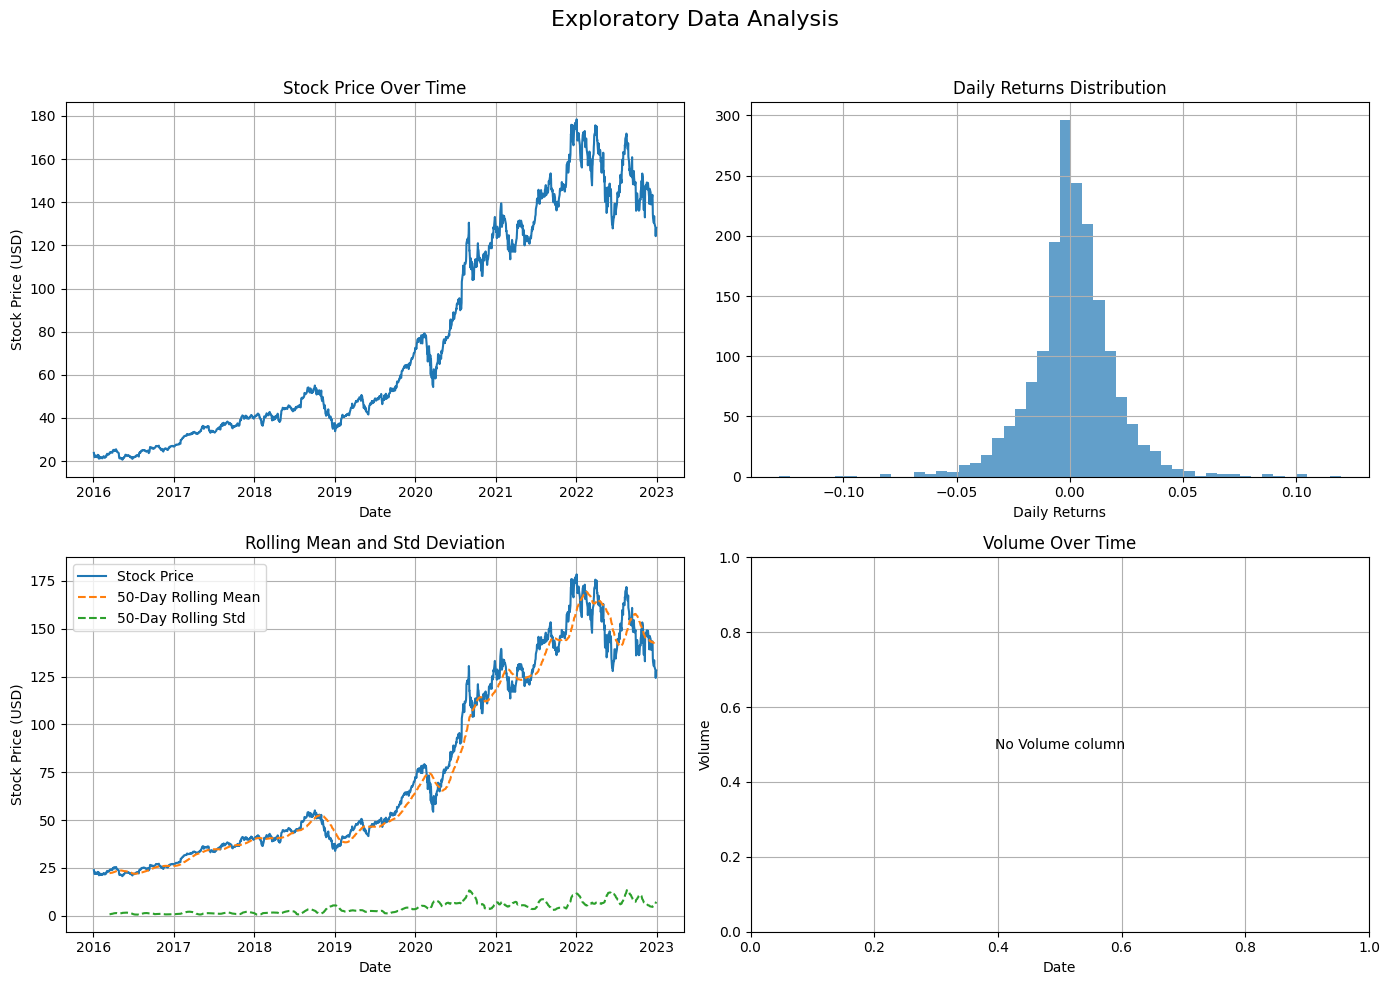

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Exploratory Data Analysis", fontsize=16)

# 1) Price
axes[0,0].plot(stock_data.index, stock_data["Close"])
axes[0,0].set_title("Stock Price Over Time")
axes[0,0].set_xlabel("Date"); axes[0,0].set_ylabel("Stock Price (USD)")
axes[0,0].grid(True)

# 2) Return histogram
returns = stock_data["Close"].pct_change().dropna()
axes[0,1].hist(returns, bins=50, alpha=0.7)
axes[0,1].set_title("Daily Returns Distribution")
axes[0,1].set_xlabel("Daily Returns"); axes[0,1].grid(True)

# 3) Rolling mean/std (window adapts to data length)
window = 50 if len(stock_data) >= 100 else 10
axes[1,0].plot(stock_data.index, stock_data["Close"], label="Stock Price")
axes[1,0].plot(stock_data.index, stock_data["Close"].rolling(window).mean(),
               linestyle="--", label=f"{window}-Day Rolling Mean")
axes[1,0].plot(stock_data.index, stock_data["Close"].rolling(window).std(),
               linestyle="--", label=f"{window}-Day Rolling Std")
axes[1,0].set_title("Rolling Mean and Std Deviation")
axes[1,0].set_xlabel("Date"); axes[1,0].set_ylabel("Stock Price (USD)")
axes[1,0].legend(); axes[1,0].grid(True)

# 4) Volume (only if present)
axes[1,1].set_title("Volume Over Time"); axes[1,1].set_xlabel("Date"); axes[1,1].set_ylabel("Volume"); axes[1,1].grid(True)
if stock_data["Volume"].notna().any():
    axes[1,1].plot(stock_data.index, stock_data["Volume"])
else:
    axes[1,1].text(0.5, 0.5, "No Volume column", ha="center", va="center", transform=axes[1,1].transAxes)

plt.tight_layout(rect=[0,0,1,0.96])
plt.show()


/tmp/ipython-input-723655752.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv("data/portfolio_data.csv", index_col=0, parse_dates=True)


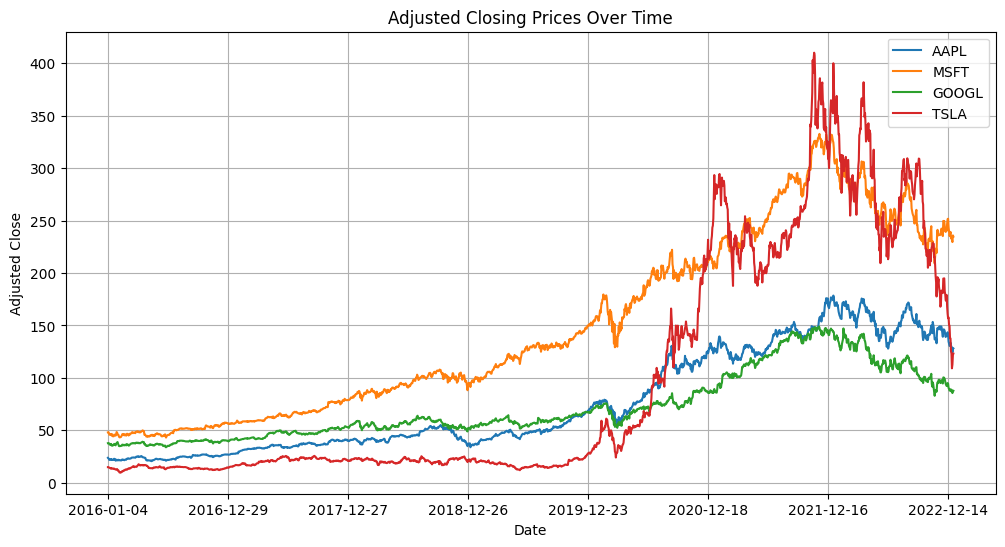

Dtypes: {'AAPL': dtype('float64'), 'MSFT': dtype('float64'), 'GOOGL': dtype('float64'), 'TSLA': dtype('float64')}
Shape used for plot: (1762, 4)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1) Load the CSV robustly (works whether Date is index or first column)
df = pd.read_csv("data/portfolio_data.csv")
# If the first column is the date index, move it into the index
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df = df.set_index("Date")
else:
    # first column is the index
    df = pd.read_csv("data/portfolio_data.csv", index_col=0, parse_dates=True)

# 2) Clean headers and ensure numeric
df.columns = df.columns.str.strip()                # remove stray spaces
tickers = ["AAPL","MSFT","GOOGL","TSLA"]
present = [t for t in tickers if t in df.columns]  # only tickers that actually exist
if not present:
    raise ValueError(f"No expected ticker columns found. Got: {df.columns.tolist()}")

# convert to numeric (coerce any bad strings to NaN)
df[present] = df[present].apply(pd.to_numeric, errors="coerce")

# drop rows where all selected tickers are NaN
df = df.dropna(how="all", subset=present)

# 3) Plot
ax = df[present].plot(figsize=(12,6))
ax.set_title("Adjusted Closing Prices Over Time")
ax.set_ylabel("Adjusted Close")
ax.set_xlabel("Date")
ax.grid(True)
plt.show()

print("Dtypes:", df[present].dtypes.to_dict())
print("Shape used for plot:", df[present].shape)


In [ ]:
# build stock_data from the merged CSV (no Volume in this file)
ticker = "AAPL"
stock_data = pd.DataFrame({"Close": df[ticker]}).dropna()

# optional: fetch volume from yfinance if you want the volume subplot
# import yfinance as yf
# v = yf.download(ticker, start=df.index.min(), end=df.index.max(), auto_adjust=False)[["Volume"]]
# stock_data = stock_data.join(v, how="left")


/tmp/ipython-input-3209921964.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv("data/portfolio_data.csv", index_col=0, parse_dates=True)


✅ Optimization status: Optimization terminated successfully

Optimized Weights:
  AAPL: 37.729%
  MSFT: 40.948%
  GOOGL: 2.000%
  TSLA: 19.323%

Annualized Return:    31.25%
Annualized Volatility:28.99%
Sharpe Ratio:         1.08


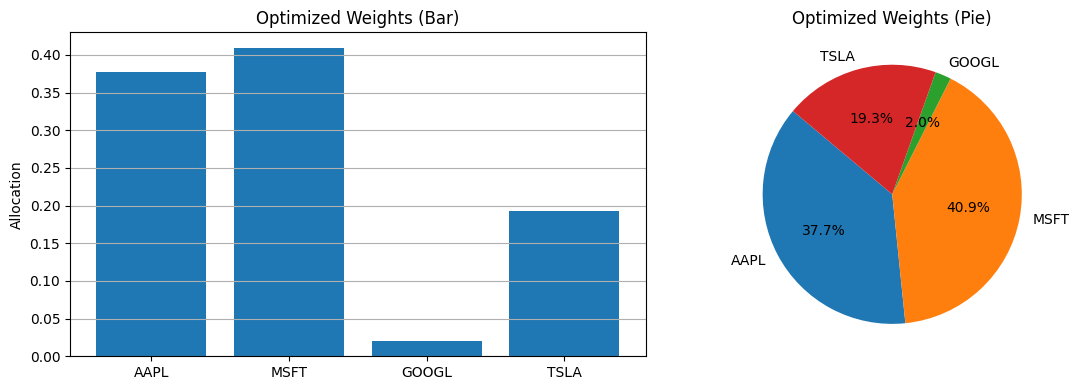

In [ ]:
# 🔥 REAL Sharpe-ratio optimization (long-only, fully invested)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- 1) Load prices (from CSV if present; else download) ---
tickers = ["AAPL","MSFT","GOOGL","TSLA"]

def load_prices():
    try:
        df = pd.read_csv("data/portfolio_data.csv", index_col=0, parse_dates=True)
        # keep only the tickers we care about and coerce to numeric
        cols = [c for c in tickers if c in df.columns]
        if not cols:
            raise RuntimeError("No expected tickers in CSV.")
        df = df[cols].apply(pd.to_numeric, errors="coerce").dropna(how="all")
        return df
    except Exception:
        import yfinance as yf
        frames = []
        for t in tickers:
            d = yf.download(t, start="2016-01-01", end="2022-12-31", auto_adjust=False)
            d = d[["Adj Close"]].rename(columns={"Adj Close": t})
            frames.append(d)
        out = pd.concat(frames, axis=1)
        out.index.name = "Date"
        return out.dropna(how="all")

prices = load_prices().dropna()
assert not prices.empty, "No price data available."

# --- 2) Compute returns, annualized mean & covariance ---
daily_ret = prices.pct_change().dropna()
trading_days = 252
mu  = daily_ret.mean().values * trading_days          # expected annual return vector
cov = (daily_ret.cov().values) * trading_days         # annualized covariance matrix
n = len(mu)

# --- 3) Optimize: maximize Sharpe => minimize negative Sharpe ---
rf = 0.0  # set risk-free (change if you want)
eps = 1e-12

def neg_sharpe(w, mu, cov, rf):
    ret = w @ mu
    vol = np.sqrt(w @ cov @ w) + eps
    return -(ret - rf) / vol

x0 = np.ones(n) / n                 # start at equal weights
bounds = [(0.02, 1.0)] * n           # long-only
cons = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]  # fully invested

res = minimize(neg_sharpe, x0, args=(mu, cov, rf),
               method="SLSQP", bounds=bounds, constraints=cons, options={"maxiter": 1000})

w = res.x
ret = float(w @ mu)
vol = float(np.sqrt(w @ cov @ w))
sharpe = (ret - rf) / (vol + eps)

# --- 4) Show results ---
print("✅ Optimization status:", res.message)
print("\nOptimized Weights:")
for t, wi in zip(tickers, w):
    print(f"  {t}: {wi:.3%}")

print(f"\nAnnualized Return:    {ret:.2%}")
print(f"Annualized Volatility:{vol:.2%}")
print(f"Sharpe Ratio:         {sharpe:.2f}")

# --- 5) Plot the optimized allocation ---
fig, ax = plt.subplots(1,2, figsize=(12,4))

ax[0].bar(tickers, w)
ax[0].set_title("Optimized Weights (Bar)")
ax[0].set_ylabel("Allocation")
ax[0].grid(True, axis='y')

ax[1].pie(w, labels=tickers, autopct='%1.1f%%', startangle=140)
ax[1].set_title("Optimized Weights (Pie)")

plt.tight_layout()
plt.show()
